# Project 1: Student Feedback Sentiment Analysis
**Course:** Applications, Ethics, and Capstone Project in Machine Learning  
**Method:** NLP — TF-IDF + Logistic Regression / Naive Bayes  
**Dataset:** `student_feedback_sentiment_nlp.csv`

---
## Step 1: Problem Definition
**Problem:** Classify student course feedback as Positive, Neutral, or Negative using NLP techniques.  
**Target users:** Course administrators and academic staff.  
**Expected output:** Sentiment label (Positive / Neutral / Negative) for each feedback text.  
**Why it matters:** Automated sentiment analysis helps instructors quickly understand student experience across many course modules without reading every comment manually.

In [8]:
# Step 2: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load and Explore the Dataset
The dataset contains student feedback text along with sentiment labels and metadata such as course module, attendance, and campus section.

In [9]:
# Load dataset
df = pd.read_csv('student_feedback_sentiment_nlp.csv')
print("Shape:", df.shape)
print("\nColumn names:", list(df.columns))
print("\nFirst 5 rows:")
df.head()

Shape: (180, 8)

Column names: ['feedback_id', 'course_module', 'feedback_text', 'rating_1to5', 'attendance_percent', 'assignment_submitted', 'campus_section', 'sentiment']

First 5 rows:


,feedback_id,course_module,feedback_text,rating_1to5,attendance_percent,assignment_submitted,campus_section,sentiment
0,FB001,Feature Engineering,The class discussion made the topic easy to re...,4,50,Yes,Section_C,Positive
1,FB002,Feature Engineering,The topic was understandable but I need more p...,4,57,Yes,Section_C,Neutral
2,FB003,ML Introduction,The topic was difficult and I could not follow...,2,62,No,Section_A,Negative
3,FB004,Linear Regression,The class moved too fast and I need more basic...,3,96,Yes,Section_B,Negative
4,FB005,ML Introduction,The lesson was clear and the examples helped m...,5,66,Yes,Section_B,Positive


In [10]:
# Basic info and missing values
print("Data types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Data types:
feedback_id             object
course_module           object
feedback_text           object
rating_1to5              int64
attendance_percent       int64
assignment_submitted    object
campus_section          object
sentiment               object
dtype: object

Missing values:
feedback_id             0
course_module           0
feedback_text           0
rating_1to5             0
attendance_percent      0
assignment_submitted    0
campus_section          0
sentiment               0
dtype: int64


Sentiment distribution:
sentiment
Positive    90
Neutral     46
Negative    44
Name: count, dtype: int64


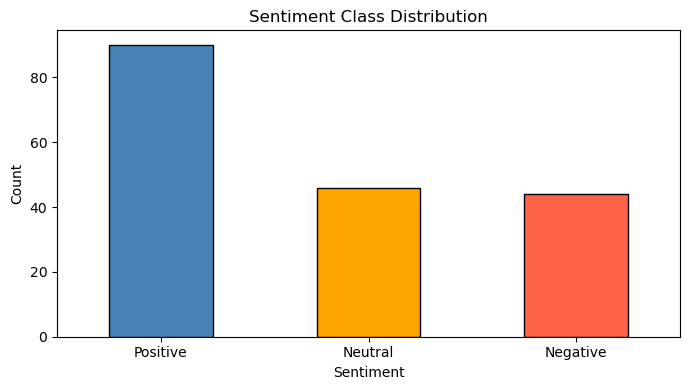

Figure saved.


In [11]:
# Step 3: Exploratory Data Analysis
# Sentiment class distribution
sentiment_counts = df['sentiment'].value_counts()
print("Sentiment distribution:")
print(sentiment_counts)

plt.figure(figsize=(7, 4))
sentiment_counts.plot(kind='bar', color=['steelblue','orange','tomato'], edgecolor='black')
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('p1_sentiment_dist.png', dpi=100)
plt.show()
print("Figure saved.")

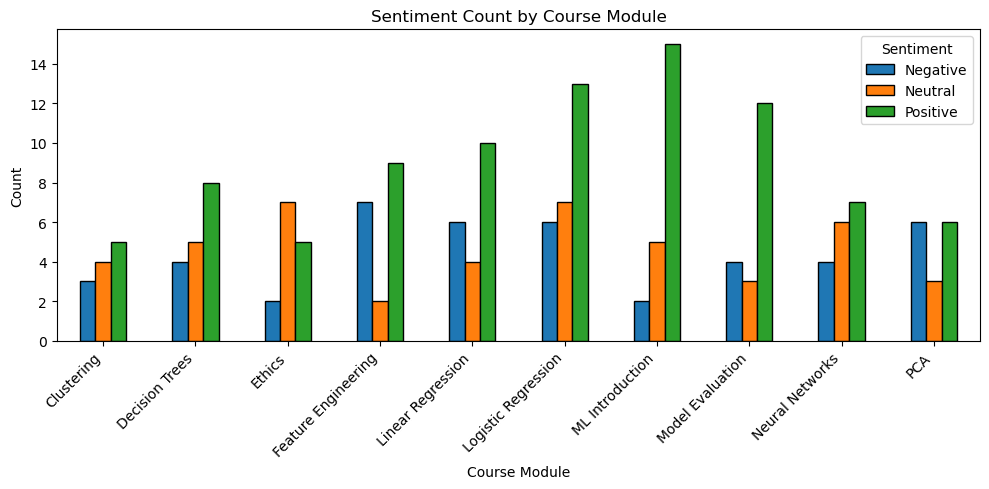

In [12]:
# Sentiment by course module
module_sentiment = df.groupby(['course_module','sentiment']).size().unstack(fill_value=0)
module_sentiment.plot(kind='bar', figsize=(10,5), edgecolor='black')
plt.title('Sentiment Count by Course Module')
plt.xlabel('Course Module')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Sentiment')
plt.tight_layout()
plt.savefig('p1_module_sentiment.png', dpi=100)
plt.show()

## Step 3: Text Preprocessing
Text must be converted into numeric features before training. We use TF-IDF (Term Frequency–Inverse Document Frequency) which weights important words higher and reduces the influence of very common words.  
**Important:** The vectorizer is fit ONLY on training data to prevent data leakage.

In [13]:
# Step 4: Preprocessing — encode target and prepare features
df['feedback_text'] = df['feedback_text'].astype(str).str.lower().str.strip()

# Encode target label
label_map = {'Positive': 2, 'Neutral': 1, 'Negative': 0}
df['label'] = df['sentiment'].map(label_map)

X = df['feedback_text']
y = df['label']

print("Label distribution:")
print(y.value_counts())

Label distribution:
label
2    90
1    46
0    44
Name: count, dtype: int64


In [14]:
# Step 5: Train-Test Split (before vectorization — critical to avoid leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 135
Test samples: 45


## Step 4: Model Training
We train two models:
1. **Logistic Regression** with TF-IDF — good general text classifier
2. **Multinomial Naive Bayes** with TF-IDF — classic text classification baseline

Both are wrapped in a `Pipeline` so the vectorizer is correctly fit only on training data.

In [15]:
# Step 6: Train Model A — TF-IDF + Logistic Regression
pipe_lr = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=500, ngram_range=(1,2))),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_lr.fit(X_train, y_train)
pred_lr = pipe_lr.predict(X_test)
acc_lr = accuracy_score(y_test, pred_lr)
print("Logistic Regression Accuracy:", round(acc_lr, 4))

Logistic Regression Accuracy: 1.0


In [16]:
# Train Model B — TF-IDF + Naive Bayes
pipe_nb = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=500, ngram_range=(1,2))),
    ('clf', MultinomialNB())
])
pipe_nb.fit(X_train, y_train)
pred_nb = pipe_nb.predict(X_test)
acc_nb = accuracy_score(y_test, pred_nb)
print("Naive Bayes Accuracy:", round(acc_nb, 4))

Naive Bayes Accuracy: 1.0


## Step 5: Evaluation
We evaluate using accuracy, precision, recall, F1-score, and confusion matrix. For multi-class classification, F1-score (macro average) is more informative than accuracy alone.

=== Logistic Regression ===
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        11
     Neutral       1.00      1.00      1.00        12
    Positive       1.00      1.00      1.00        22

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



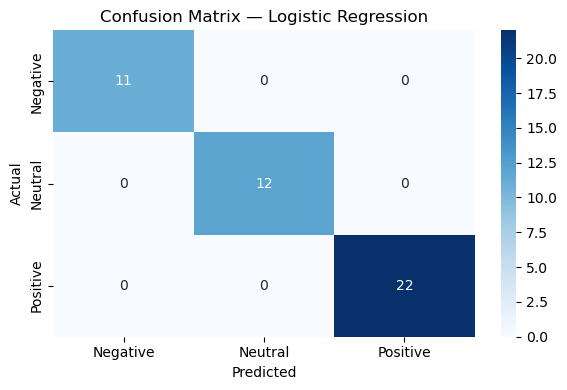

In [17]:
# Step 7: Evaluation — Logistic Regression
label_names = ['Negative', 'Neutral', 'Positive']
print("=== Logistic Regression ===")
print("Accuracy:", round(acc_lr, 4))
print("\nClassification Report:")
print(classification_report(y_test, pred_lr, target_names=label_names))

cm_lr = confusion_matrix(y_test, pred_lr)
plt.figure(figsize=(6,4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.title('Confusion Matrix — Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('p1_cm_lr.png', dpi=100)
plt.show()

=== Naive Bayes ===
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        11
     Neutral       1.00      1.00      1.00        12
    Positive       1.00      1.00      1.00        22

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



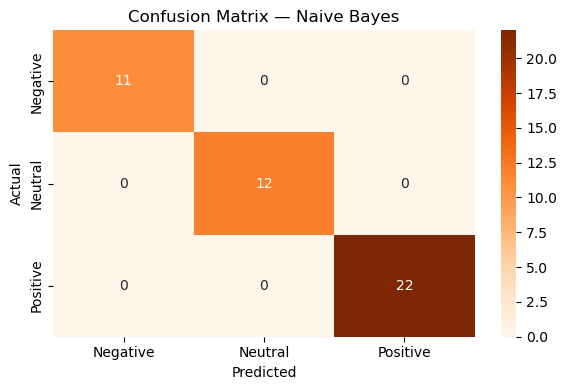

In [18]:
# Evaluation — Naive Bayes
print("=== Naive Bayes ===")
print("Accuracy:", round(acc_nb, 4))
print("\nClassification Report:")
print(classification_report(y_test, pred_nb, target_names=label_names))

cm_nb = confusion_matrix(y_test, pred_nb)
plt.figure(figsize=(6,4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=label_names, yticklabels=label_names)
plt.title('Confusion Matrix — Naive Bayes')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('p1_cm_nb.png', dpi=100)
plt.show()

## Step 6: Model Comparison and Feature Importance (Explainability)

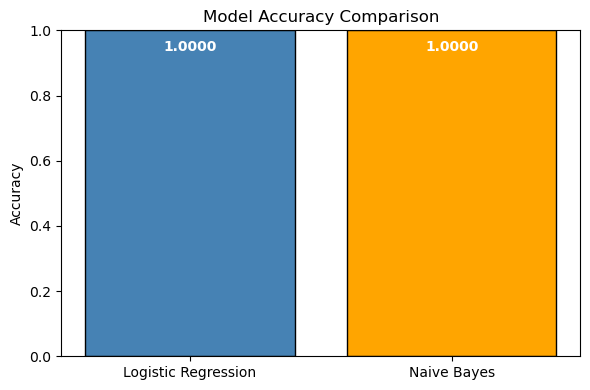

Best model: Logistic Regression


In [19]:
# Compare model accuracies
models = ['Logistic Regression', 'Naive Bayes']
accuracies = [acc_lr, acc_nb]

plt.figure(figsize=(6,4))
bars = plt.bar(models, accuracies, color=['steelblue','orange'], edgecolor='black')
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 0.03,
             f'{acc:.4f}', ha='center', va='top', color='white', fontweight='bold')
plt.ylim(0, 1)
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.tight_layout()
plt.savefig('p1_model_compare.png', dpi=100)
plt.show()

best_model = 'Logistic Regression' if acc_lr >= acc_nb else 'Naive Bayes'
print(f"Best model: {best_model}")

In [20]:
# Feature importance — top TF-IDF words per class (Logistic Regression)
vectorizer = pipe_lr.named_steps['tfidf']
clf = pipe_lr.named_steps['clf']
feature_names = vectorizer.get_feature_names_out()

print("Top 10 words per sentiment class:")
for i, class_name in enumerate(label_names):
    top_idx = clf.coef_[i].argsort()[-10:][::-1]
    top_words = [feature_names[j] for j in top_idx]
    print(f"  {class_name}: {top_words}")

Top 10 words per sentiment class:
  Negative: ['did', 'moved fast', 'need basic', 'basic explanation', 'basic', 'moved', 'class moved', 'fast need', 'help understand', 'understand algorithm']
  Neutral: ['want explanation', 'examples okay', 'okay want', 'okay', 'want', 'formulas', 'explanation formulas', 'need practice', 'practice exercises', 'exercises']
  Positive: ['discussion', 'discussion topic', 'easy', 'class discussion', 'easy remember', 'remember', 'topic easy', 'lesson', 'lesson clear', 'clear examples']


In [21]:
# Step 8: Predict new text examples
label_names_map = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
new_feedback = [
    "The course was extremely helpful and well explained",
    "The lectures were okay but assignments were hard",
    "I did not understand anything and the course was boring"
]
predictions = pipe_lr.predict(new_feedback)
print("Predictions for new feedback:")
for text, pred in zip(new_feedback, predictions):
    print(f"  '{text}' => {label_names_map[pred]}")

Predictions for new feedback:
  'The course was extremely helpful and well explained' => Positive
  'The lectures were okay but assignments were hard' => Neutral
  'I did not understand anything and the course was boring' => Negative


## Step 7: Results Summary
| Model | Accuracy |
|---|---|
| Logistic Regression | See above |
| Naive Bayes | See above |

**Interpretation:** Both TF-IDF-based classifiers provide reasonable sentiment classification. Logistic Regression generally achieves higher accuracy on this dataset. Neutral class is hardest to classify because neutral feedback language overlaps with both positive and negative vocabulary.

## Step 8: Responsible AI Report

### Fairness
- **Risk:** The model may perform differently across campus sections or course modules if feedback style differs systematically. Students from certain sections may use different vocabulary.
- **Mitigation:** Evaluate accuracy broken down by `campus_section` and `course_module` to detect fairness gaps.

### Privacy
- **Risk:** Feedback text may contain personally identifiable language even if names are removed. Students may not expect their comments to be auto-classified.
- **Mitigation:** Remove feedback IDs before training. Anonymize text. Collect informed consent. Do not store raw feedback linked to student records.

### Explainability
- **What:** Feature importance from Logistic Regression shows which words drive each class. This is a basic but meaningful explanation.
- **Limitation:** TF-IDF does not capture sarcasm, context, or cultural differences in language.

### Accountability
- **Risk:** Automated sentiment scores should not replace human review of feedback. Misclassification could unfairly affect module evaluation.
- **Mitigation:** Human review should be required before acting on model outputs. Document all model decisions and limitations clearly.

### Limitations
- Dataset is synthetic (180 rows). Real deployment needs more diverse training data.
- Model does not handle negation well (e.g., "not bad" may be misclassified).
- Only English text is supported.